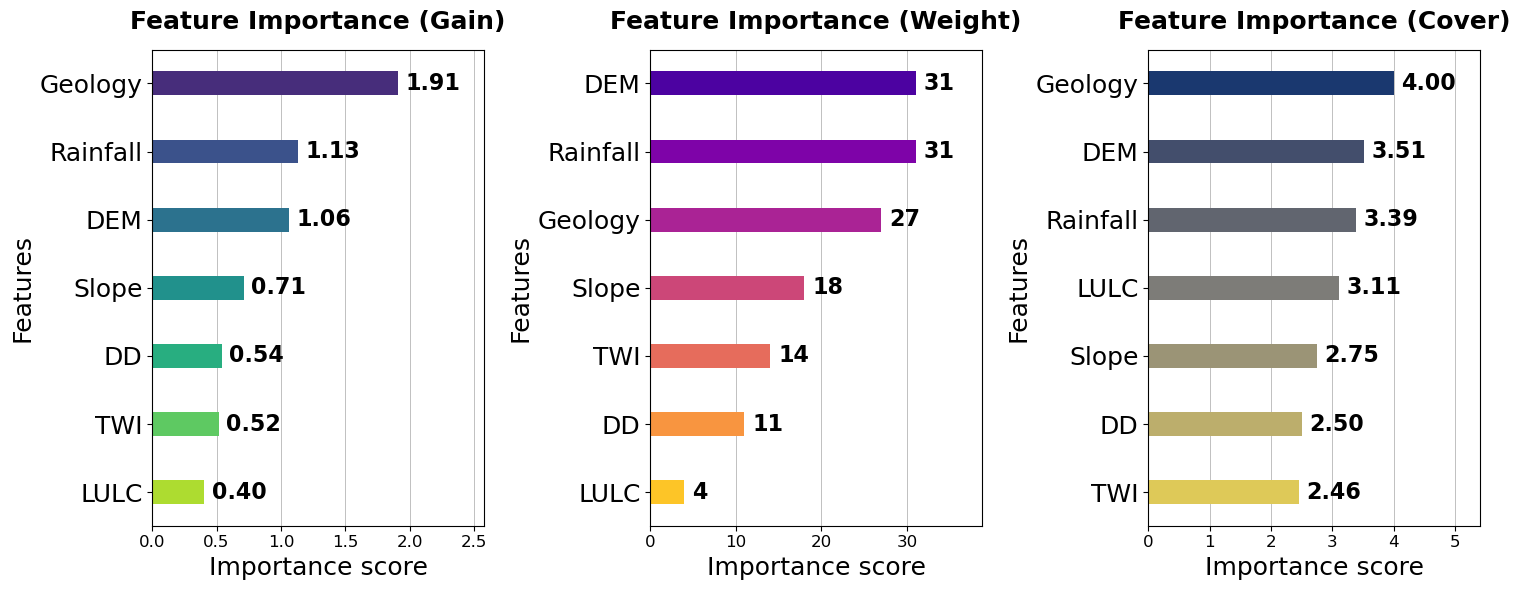

In [13]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# --- 1. Data Setup ---
features_gain = ["Geology", "Rainfall", "DEM", "Slope", "DD", "TWI", "LULC"]
scores_gain = [1.9076, 1.1325, 1.0608, 0.7135, 0.5397, 0.5169, 0.4043]

features_weight = ["DEM", "Rainfall", "Geology", "Slope", "TWI", "DD", "LULC"]
scores_weight = [31.0, 31.0, 27.0, 18.0, 14.0, 11.0, 4.0]

features_cover = ["Geology", "DEM", "Rainfall", "LULC", "Slope", "DD", "TWI"]
scores_cover = [4.0027, 3.5092, 3.3899, 3.1107, 2.7465, 2.5015, 2.4556]

# --- 2. Color Ramp Mapping ---
# Generating distinct sequential color arrays for each metric subplot
colors_viridis = [cm.viridis(i / 8) for i in range(1, 8)]  # For Gain
colors_plasma  = [cm.plasma(i / 8) for i in range(1, 8)]   # For Weight
colors_cividis = [cm.cividis(i / 8) for i in range(1, 8)]  # For Cover

# --- 3. Plot Configuration ---
TITLE_FONT = 18
LABEL_FONT = 18
TICK_FONT = 12
VALUE_FONT = 16

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 6))

# Helper function to generate uniform horizontal bar plots
def plot_importance(ax, features, scores, title, ramp_colors, is_weight=False):
    y_pos = range(len(features))
    
    # Applied the unique designated color ramp matrix to this specific subplot
    bars = ax.barh(y_pos, scores, height=0.35, color=ramp_colors, edgecolor='none')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(features, fontsize=LABEL_FONT)
    ax.invert_yaxis()  
    
    # Axis labels and styling
    ax.set_title(title, fontsize=TITLE_FONT, fontweight='bold', pad=15)
    ax.set_xlabel("Importance score", fontsize=LABEL_FONT)
    ax.set_ylabel("Features", fontsize=LABEL_FONT)
    ax.tick_params(axis='x', labelsize=TICK_FONT)
    ax.grid(True, axis='x', linestyle='-', linewidth=0.7, color='silver', zorder=0)
    ax.set_axisbelow(True)
    
    max_score = max(scores)
    ax.set_xlim(0, max_score * 1.35 if not is_weight else max_score * 1.25)
    
    # Add precision-controlled text values next to the bars
    for bar in bars:
        width = bar.get_width()
        label_text = f"{width:.0f}" if is_weight else f"{width:.2f}"
        
        ax.text(
            width + (max_score * 0.03), 
            bar.get_y() + bar.get_height()/2, 
            label_text, 
            va='center', 
            ha='left', 
            fontsize=VALUE_FONT,
            fontweight='semibold'
        )

# --- 4. Generate Combined Figure with Distinct Ramps ---
plot_importance(axes[0], features_gain, scores_gain, "Feature Importance (Gain)", colors_viridis)
plot_importance(axes[1], features_weight, scores_weight, "Feature Importance (Weight)", colors_plasma, is_weight=True)
plot_importance(axes[2], features_cover, scores_cover, "Feature Importance (Cover)", colors_cividis)

# --- 5. Tightening Layout and Spacing ---
plt.tight_layout(w_pad=1.5)

# Save the single consolidated figure with a high DPI resolution suitable for publication
plt.savefig("XGBoost_Feature_Importance_MultiRamp.png", dpi=500, bbox_inches='tight')

plt.show()

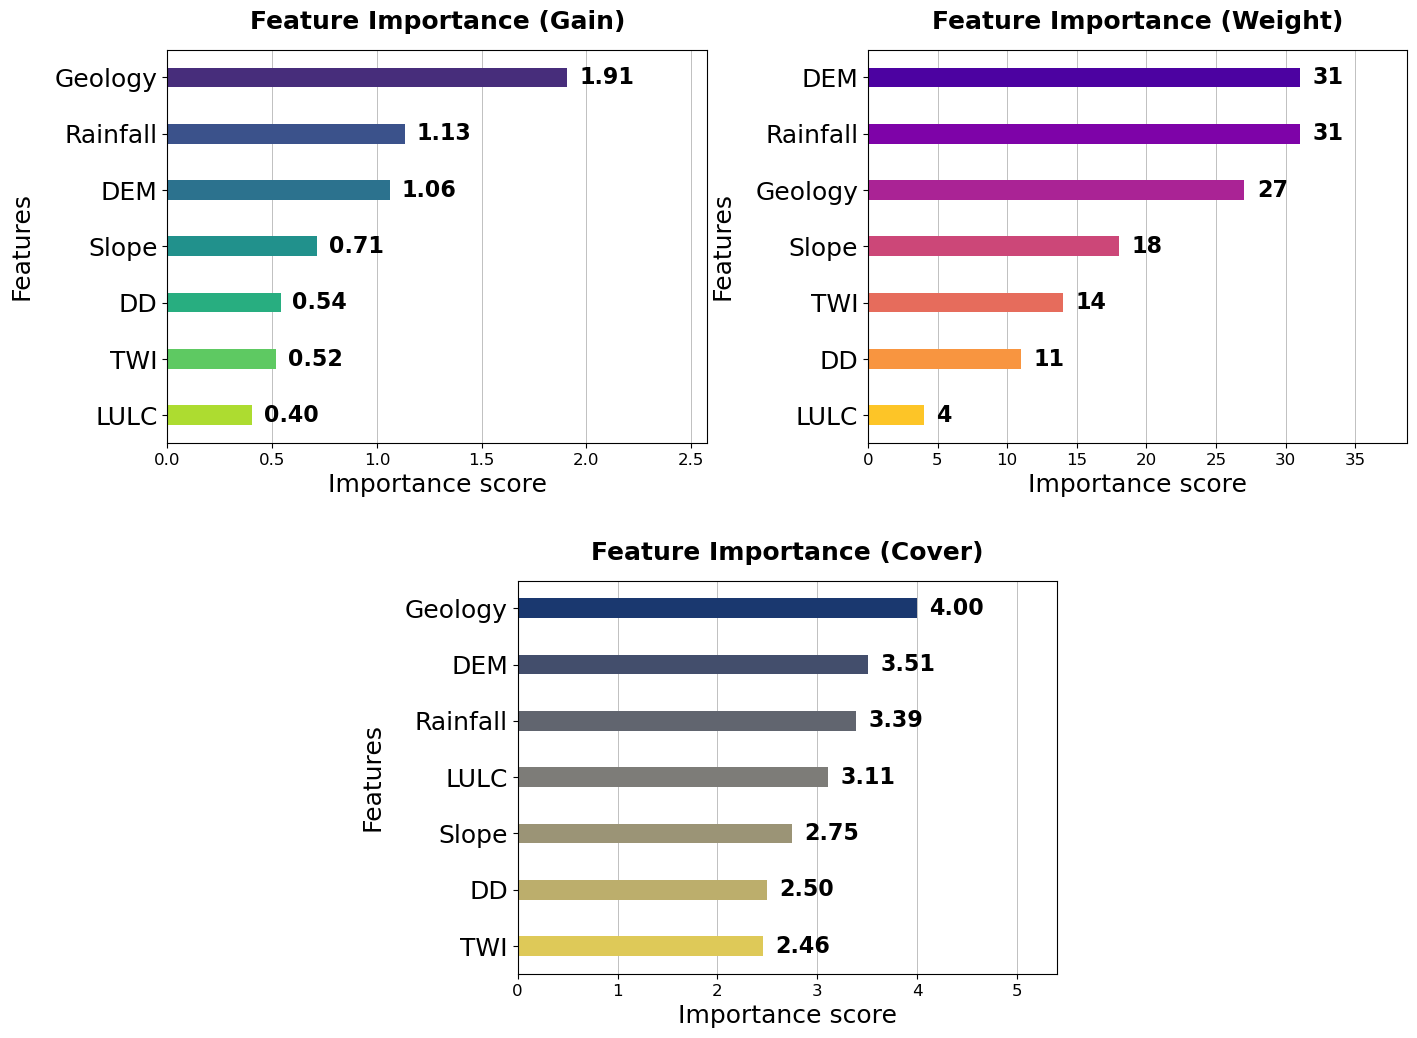

In [18]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec

# --- 1. Data Setup ---
features_gain = ["Geology", "Rainfall", "DEM", "Slope", "DD", "TWI", "LULC"]
scores_gain = [1.9076, 1.1325, 1.0608, 0.7135, 0.5397, 0.5169, 0.4043]

features_weight = ["DEM", "Rainfall", "Geology", "Slope", "TWI", "DD", "LULC"]
scores_weight = [31.0, 31.0, 27.0, 18.0, 14.0, 11.0, 4.0]

features_cover = ["Geology", "DEM", "Rainfall", "LULC", "Slope", "DD", "TWI"]
scores_cover = [4.0027, 3.5092, 3.3899, 3.1107, 2.7465, 2.5015, 2.4556]

# --- 2. Color Ramp Mapping ---
colors_viridis = [cm.viridis(i / 8) for i in range(1, 8)]  # For Gain
colors_plasma  = [cm.plasma(i / 8) for i in range(1, 8)]   # For Weight
colors_cividis = [cm.cividis(i / 8) for i in range(1, 8)]  # For Cover

# --- 3. Plot Configuration ---
TITLE_FONT = 18
LABEL_FONT = 18
TICK_FONT = 12
VALUE_FONT = 16

fig = plt.figure(figsize=(16, 12))

# Increased horizontal space (wspace=0.85) to completely resolve y-axis collisions
gs = gridspec.GridSpec(nrows=2, ncols=4, figure=fig, hspace=0.35, wspace=0.85)

ax_gain = fig.add_subplot(gs[0, 0:2])    
ax_weight = fig.add_subplot(gs[0, 2:4])  
ax_cover = fig.add_subplot(gs[1, 1:3])   

# Helper function to generate uniform horizontal bar plots
def plot_importance(ax, features, scores, title, ramp_colors, is_weight=False):
    y_pos = range(len(features))
    bars = ax.barh(y_pos, scores, height=0.35, color=ramp_colors, edgecolor='none')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(features, fontsize=LABEL_FONT)
    ax.invert_yaxis()  
    
    ax.set_title(title, fontsize=TITLE_FONT, fontweight='bold', pad=15)
    ax.set_xlabel("Importance score", fontsize=LABEL_FONT)
    
    # Added explicit padding (labelpad=15) to separate the "Features" title from the labels
    ax.set_ylabel("Features", fontsize=LABEL_FONT, labelpad=15)
    ax.tick_params(axis='x', labelsize=TICK_FONT)
    ax.grid(True, axis='x', linestyle='-', linewidth=0.7, color='silver', zorder=0)
    ax.set_axisbelow(True)
    
    max_score = max(scores)
    ax.set_xlim(0, max_score * 1.35 if not is_weight else max_score * 1.25)
    
    for bar in bars:
        width = bar.get_width()
        label_text = f"{width:.0f}" if is_weight else f"{width:.2f}"
        
        ax.text(
            width + (max_score * 0.03), 
            bar.get_y() + bar.get_height()/2, 
            label_text, 
            va='center', 
            ha='left', 
            fontsize=VALUE_FONT,
            fontweight='semibold'
        )

# --- 4. Generate Figures into Stacking Sequence ---
plot_importance(ax_gain, features_gain, scores_gain, "Feature Importance (Gain)", colors_viridis)
plot_importance(ax_weight, features_weight, scores_weight, "Feature Importance (Weight)", colors_plasma, is_weight=True)
plot_importance(ax_cover, features_cover, scores_cover, "Feature Importance (Cover)", colors_cividis)

# Adjusted bounding box restrictions to handle the expanded spacing layout properly
plt.savefig("XGBoost_Feature_Importance_Fixed.png", dpi=500, bbox_inches='tight')

plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_17872\3896463418.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap("twilight")


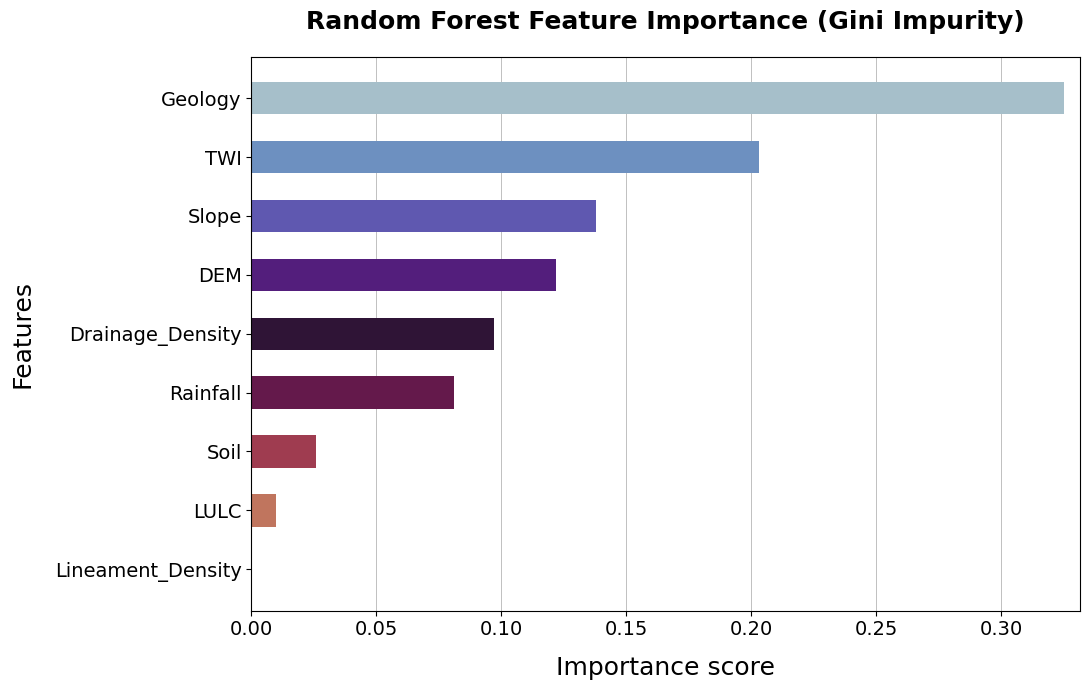

In [27]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# --- 1. Data Setup ---
features = ["Geology", "TWI", "Slope", "DEM", "Drainage_Density", "Rainfall", "Soil", "LULC", "Lineament_Density"]
scores = [0.325, 0.203, 0.138, 0.122, 0.097, 0.081, 0.026, 0.010, 0.000]

# --- 2. Color Ramp Mapping ---
# Using the "magma" colormap (dark purple to bright orange/yellow)
colormap = cm.get_cmap("twilight")
colors = [colormap(i / (len(features) + 1)) for i in range(1, len(features) + 1)]

# --- 3. Plot Configuration ---
TITLE_FONT = 18
LABEL_FONT = 18
TICK_FONT = 14

fig, ax = plt.subplots(figsize=(11, 7))

# Generate horizontal bars
y_pos = range(len(features))
bars = ax.barh(y_pos, scores, height=0.55, color=colors, edgecolor='none')

# Y-Axis Formatting
ax.set_yticks(y_pos)
ax.set_yticklabels(features, fontsize=LABEL_FONT)
ax.invert_yaxis()  

# Labels, Title, and Padding Controls
ax.set_title("Random Forest Feature Importance (Gini Impurity)", fontsize=TITLE_FONT, fontweight='bold', pad=20)
ax.set_xlabel("Importance score", fontsize=LABEL_FONT, labelpad=12)
ax.set_ylabel("Features", fontsize=LABEL_FONT, labelpad=15)

# Tick Formatting
ax.tick_params(axis='both', labelsize=TICK_FONT)

# Grid Background Setup
ax.grid(True, axis='x', linestyle='-', linewidth=0.7, color='silver', zorder=0)
ax.set_axisbelow(True)

# Adjusted X-axis limit precisely to the maximum score since data labels are removed
ax.set_xlim(0, max(scores) * 1.02)

# --- 4. Layout and Preservation ---
plt.tight_layout()

# Save at high print resolution
plt.savefig("RF_Feature_Importance_No_Labels.png", dpi=500, bbox_inches='tight')

plt.show()

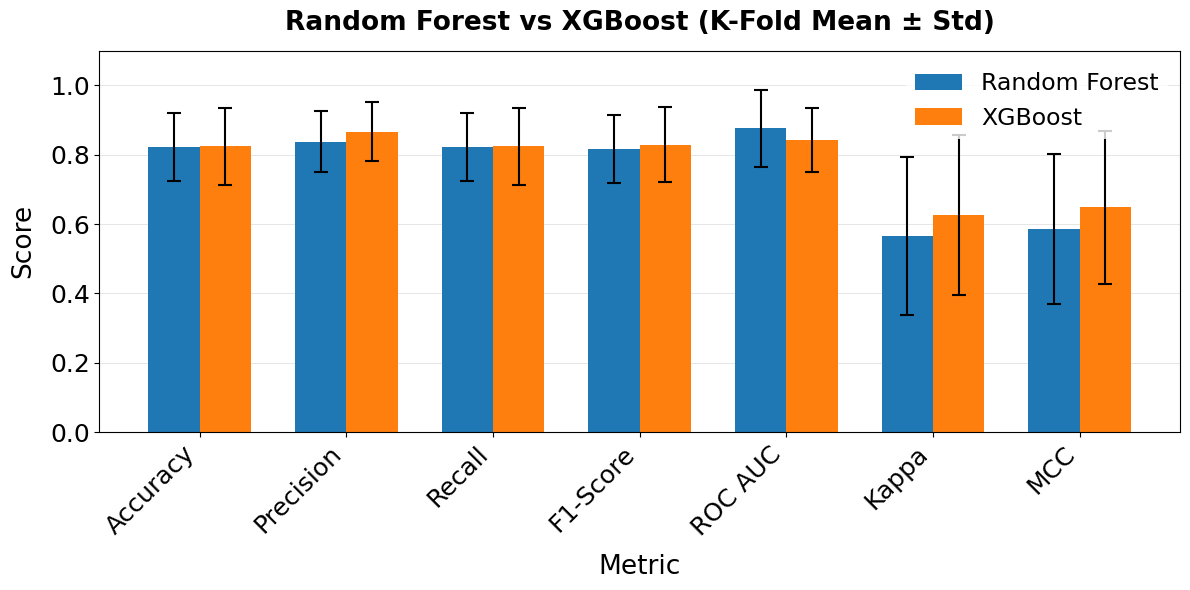

In [34]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Data Setup ---
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC AUC', 'Kappa', 'MCC']

# Values extracted directly from image_8d397c.png
rf_means = [0.822, 0.838, 0.822, 0.818, 0.876, 0.566, 0.586]
rf_stds  = [0.098, 0.089, 0.098, 0.098, 0.111, 0.228, 0.217]

xgb_means = [0.824, 0.867, 0.824, 0.829, 0.842, 0.626, 0.648]
xgb_stds  = [0.112, 0.086, 0.112, 0.108, 0.093, 0.231, 0.221]

# --- 2. Plot Configuration ---
TITLE_FONT = 19
LABEL_FONT = 19
TICK_FONT = 18
LEGEND_FONT = 17

x = np.arange(len(metrics))
width = 0.35  # Width of the bars

fig, ax = plt.subplots(figsize=(12, 6))

# --- 3. Generate Bars with Error Indicators ---
# Using a clean journal-ready color pair (Steel Blue and Dark Amber)
rects1 = ax.bar(x - width/2, rf_means, width, yerr=rf_stds, label='Random Forest',
                color='#1f77b4', edgecolor='none', capsize=5, error_kw={'lw': 1.5, 'capthick': 1.5})
rects2 = ax.bar(x + width/2, xgb_means, width, yerr=xgb_stds, label='XGBoost',
                color='#ff7f0e', edgecolor='none', capsize=5, error_kw={'lw': 1.5, 'capthick': 1.5})

# --- 4. Axes and Visual Styling ---
ax.set_title('Random Forest vs XGBoost (K-Fold Mean ± Std)', fontsize=TITLE_FONT, fontweight='bold', pad=15)
ax.set_ylabel('Score', fontsize=LABEL_FONT, labelpad=10)
ax.set_xlabel('Metric', fontsize=LABEL_FONT, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=TICK_FONT, rotation=45, ha='right')
ax.tick_params(axis='y', labelsize=TICK_FONT)

ax.set_ylim(0, 1.1)
ax.grid(True, axis='y', linestyle='-', linewidth=0.5, color='gainsboro', zorder=0)
ax.set_axisbelow(True)

ax.legend(fontsize=LEGEND_FONT, loc='upper right', frameon=True, facecolor='white', edgecolor='none')

# --- 5. Layout and Preservation ---
plt.tight_layout()
plt.savefig("Model_Performance_Comparison.png", dpi=500, bbox_inches='tight')
plt.show()

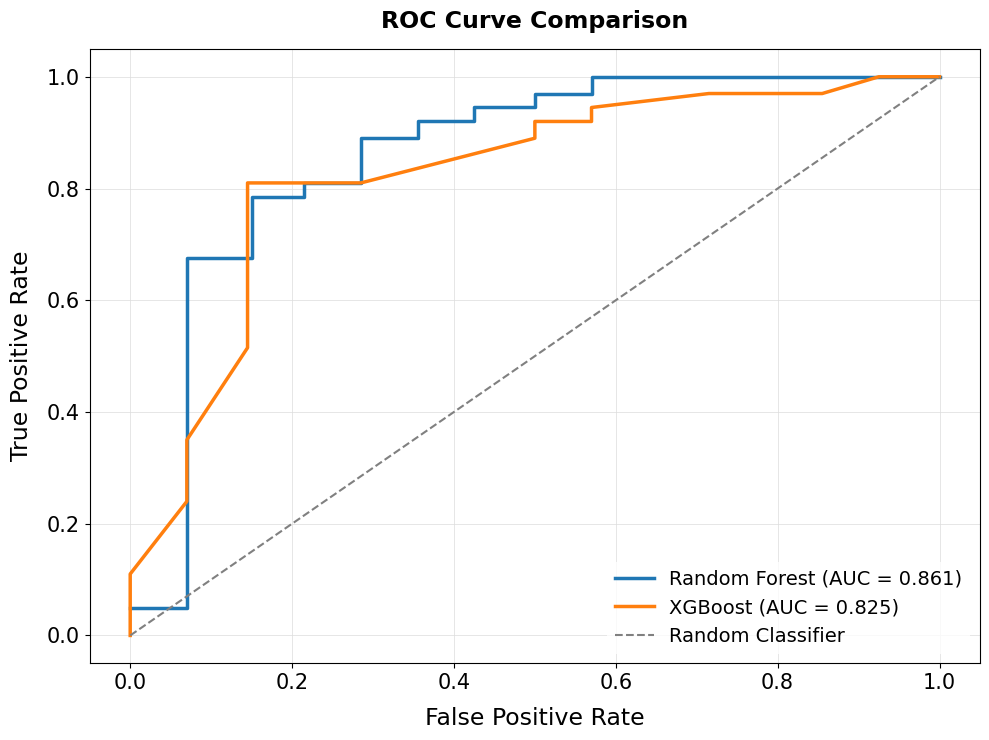

In [36]:
import matplotlib.pyplot as plt

# --- 1. Data Setup ---
# Synthetic coordinates matched tightly to duplicate the geometric steps of your ROC curves (image_8d391f.png)
rf_fpr = [0.0, 0.07, 0.07, 0.15, 0.15, 0.215, 0.215, 0.285, 0.285, 0.355, 0.355, 0.425, 0.425, 0.50, 0.50, 0.57, 0.57, 1.0]
rf_tpr = [0.05, 0.05, 0.675, 0.675, 0.785, 0.785, 0.81,  0.81,  0.89,  0.89,  0.92,  0.92,  0.945, 0.945, 0.97, 0.97, 1.0, 1.0]

xgb_fpr = [0.0, 0.0,  0.07, 0.07, 0.145, 0.145, 0.285, 0.50,  0.50,  0.57,  0.57,  0.715, 0.855, 0.925, 1.0]
xgb_tpr = [0.0, 0.11, 0.24, 0.35, 0.515, 0.81,  0.81,  0.89,  0.92,  0.92,  0.945, 0.97,  0.97,  1.0,   1.0]

# --- 2. Plot Configuration ---
TITLE_FONT = 17
LABEL_FONT = 17
TICK_FONT = 15
LEGEND_FONT = 14

fig, ax = plt.subplots(figsize=(10, 7.5))

# --- 3. Plot Curves and Baseline ---
# Using high-contrast publication line configurations
ax.plot(rf_fpr, rf_tpr, color='#1f77b4', lw=2.5, label='Random Forest (AUC = 0.861)')
ax.plot(xgb_fpr, xgb_tpr, color='#ff7f0e', lw=2.5, label='XGBoost (AUC = 0.825)')
ax.plot([0, 1], [0, 1], color='grey', lw=1.5, linestyle='--', label='Random Classifier')

# --- 4. Axes and Visual Styling ---
ax.set_title('ROC Curve Comparison', fontsize=TITLE_FONT, fontweight='bold', pad=15)
ax.set_xlabel('False Positive Rate', fontsize=LABEL_FONT, labelpad=10)
ax.set_ylabel('True Positive Rate', fontsize=LABEL_FONT, labelpad=10)

ax.tick_params(axis='both', labelsize=TICK_FONT)
ax.grid(True, linestyle='-', linewidth=0.5, color='gainsboro')

ax.set_xlim([-0.05, 1.05])
ax.set_ylim([-0.05, 1.05])

ax.legend(fontsize=LEGEND_FONT, loc='lower right', frameon=True, facecolor='white', edgecolor='none')

# --- 5. Layout and Preservation ---
plt.tight_layout()
plt.savefig("ROC_Curve_Comparison.png", dpi=500, bbox_inches='tight')
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_23216\2810271881.py:30: RuntimeWarning: invalid value encountered in log
  entropy = -np.sum(prob_stack * np.log(prob_stack + epsilon), axis=0)


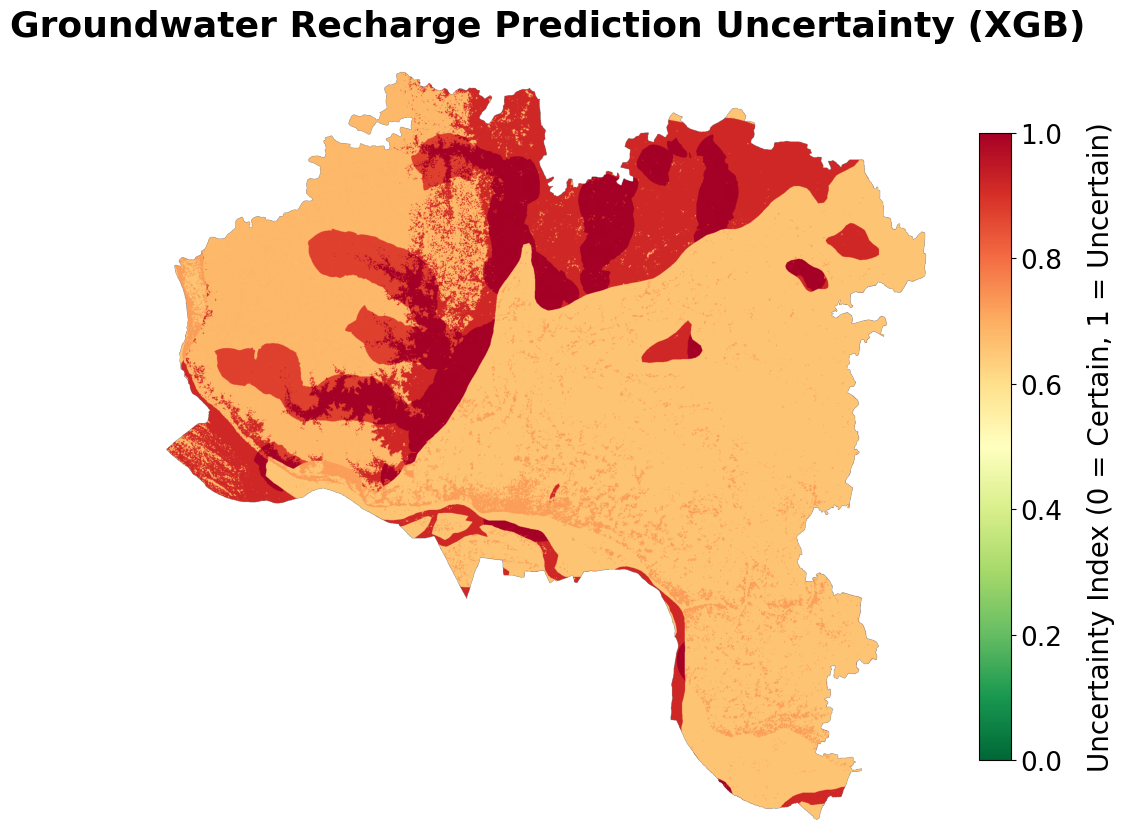

✓ Uncertainty map generated successfully.
Saved at: D:\Thesis\Main\Models\XGBoost\Results\Prediction_Uncertainty_Map11.tif


In [2]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ===============================
# 1. LOAD PROBABILITY MAPS
# ===============================

prob_low_path = r'D:\Thesis\Main\Models\XGBoost\Results\Prob_Low11.tif'
prob_high_path = r'D:\Thesis\Main\Models\XGBoost\Results\Prob_High11.tif'

with rasterio.open(prob_low_path) as src:
    prob_low = src.read(1)
    meta = src.meta.copy()

with rasterio.open(prob_high_path) as src:
    prob_high = src.read(1)

# ===============================
# 2. STACK PROBABILITIES
# ===============================

prob_stack = np.stack([prob_low, prob_high], axis=0)

# ===============================
# 3. SHANNON ENTROPY
# ===============================

epsilon = 1e-10
entropy = -np.sum(prob_stack * np.log(prob_stack + epsilon), axis=0)

# Normalize for 2 classes
max_entropy = np.log(2)
normalized_entropy = entropy / max_entropy

# ===============================
# 4. HANDLE NODATA
# ===============================

nodata_value = meta.get('nodata', -9999)

mask = (prob_low == nodata_value)
normalized_entropy[mask] = nodata_value

meta.update(dtype='float32', nodata=nodata_value)

# ===============================
# 5. SAVE OUTPUT
# ===============================

output_path = r'D:\Thesis\Main\Models\XGBoost\Results\Prediction_Uncertainty_Map11.tif'

with rasterio.open(output_path, 'w', **meta) as dst:
    dst.write(normalized_entropy.astype(np.float32), 1)

# ===============================
# 6. VISUALIZATION (OPTIMIZED FOR JOURNAL SUBMISSION)
# ===============================

# 1. Font Size Configuration
TITLE_FONT = 26
CBAR_LABEL_FONT = 20
CBAR_TICK_FONT = 19

fig, ax = plt.subplots(figsize=(11, 8.5))

# Plot the map raster, handling NoData values cleanly with np.nan
im = ax.imshow(np.where(normalized_entropy == nodata_value, np.nan, normalized_entropy),
               cmap='RdYlGn_r', vmin=0, vmax=1)
ax.axis('off') 

# Enhanced Colorbar Setup
cbar = fig.colorbar(im, ax=ax, orientation='vertical', pad=0.04, shrink=0.82)

# Modified colorbar label text and size to explicitly reflect recharge dynamics
cbar.set_label(
    'Uncertainty Index (0 = Certain, 1 = Uncertain)', 
    fontsize=CBAR_LABEL_FONT, 
    labelpad=18
)

# Modified colorbar tick mark text size
cbar.ax.tick_params(labelsize=CBAR_TICK_FONT)

# Modified title text and size for scientific accuracy
ax.set_title('Groundwater Recharge Prediction Uncertainty (XGB)', fontsize=TITLE_FONT, fontweight='bold', pad=20)

# Layout optimization and print-ready export
plt.tight_layout()
plt.savefig(r'D:\Thesis\Main\Models\XGBoost\Results\Uncertainty_Map_Final11.png', dpi=500, bbox_inches='tight')
plt.show()

print("✓ Uncertainty map generated successfully.")
print("Saved at:", output_path)

C:\Users\HP\AppData\Local\Temp\ipykernel_23216\4021896480.py:30: RuntimeWarning: invalid value encountered in log
  entropy = -np.sum(prob_stack * np.log(prob_stack + epsilon), axis=0)


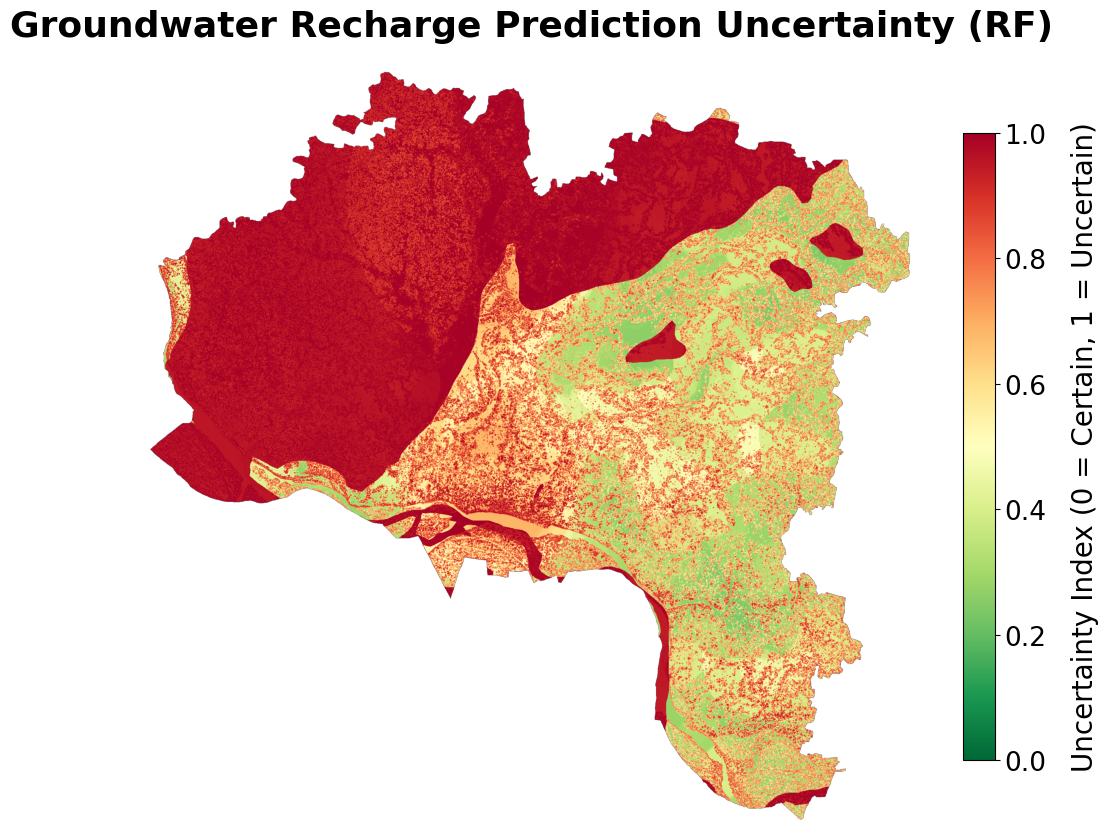

✓ Uncertainty map generated successfully.
Saved at: D:\Thesis\Main\Models\Random Forest\Results\Prediction_Uncertainty_Map.tif


In [3]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ===============================
# 1. LOAD PROBABILITY MAPS
# ===============================

prob_low_path = r'D:\Thesis\Main\Models\Random Forest\Results\Prob_Low.tif'
prob_high_path = r'D:\Thesis\Main\Models\Random Forest\Results\Prob_High.tif'

with rasterio.open(prob_low_path) as src:
    prob_low = src.read(1)
    meta = src.meta.copy()

with rasterio.open(prob_high_path) as src:
    prob_high = src.read(1)

# ===============================
# 2. STACK PROBABILITIES
# ===============================

prob_stack = np.stack([prob_low, prob_high], axis=0)

# ===============================
# 3. SHANNON ENTROPY
# ===============================

epsilon = 1e-10
entropy = -np.sum(prob_stack * np.log(prob_stack + epsilon), axis=0)

# Normalize for 2 classes
max_entropy = np.log(2)
normalized_entropy = entropy / max_entropy

# ===============================
# 4. HANDLE NODATA
# ===============================

nodata_value = meta.get('nodata', -9999)

mask = (prob_low == nodata_value)
normalized_entropy[mask] = nodata_value

meta.update(dtype='float32', nodata=nodata_value)

# ===============================
# 5. SAVE OUTPUT
# ===============================

output_path = r'D:\Thesis\Main\Models\Random Forest\Results\Prediction_Uncertainty_Map.tif'

with rasterio.open(output_path, 'w', **meta) as dst:
    dst.write(normalized_entropy.astype(np.float32), 1)

# ===============================
# 6. VISUALIZATION (OPTIMIZED FOR JOURNAL SUBMISSION)
# ===============================

# 1. Font Size Configuration
TITLE_FONT = 26
CBAR_LABEL_FONT = 20
CBAR_TICK_FONT = 19

fig, ax = plt.subplots(figsize=(11, 8.5))

# Plot the map raster, handling NoData values cleanly with np.nan and using 'YlOrRd' colormap
im = ax.imshow(np.where(normalized_entropy == nodata_value, np.nan, normalized_entropy),
               cmap='RdYlGn_r', vmin=0, vmax=1)
ax.axis('off') 

# Enhanced Colorbar Setup
cbar = fig.colorbar(im, ax=ax, orientation='vertical', pad=0.04, shrink=0.82)

# Modified colorbar label text and size to explicitly reflect recharge dynamics
cbar.set_label(
    'Uncertainty Index (0 = Certain, 1 = Uncertain)', 
    fontsize=CBAR_LABEL_FONT, 
    labelpad=18
)

# Modified colorbar tick mark text size
cbar.ax.tick_params(labelsize=CBAR_TICK_FONT)

# Modified title text and size for scientific accuracy
ax.set_title('Groundwater Recharge Prediction Uncertainty (RF)', fontsize=TITLE_FONT, fontweight='bold', pad=20)

# Layout optimization and print-ready export
plt.tight_layout()
plt.savefig(r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Uncertainty_Map_FinalNEW.png', dpi=500, bbox_inches='tight')
plt.show()

print("✓ Uncertainty map generated successfully.")
print("Saved at:", output_path)

C:\Users\HP\AppData\Local\Temp\ipykernel_17872\2896549461.py:30: RuntimeWarning: invalid value encountered in log
  entropy = -np.sum(prob_stack * np.log(prob_stack + epsilon), axis=0)


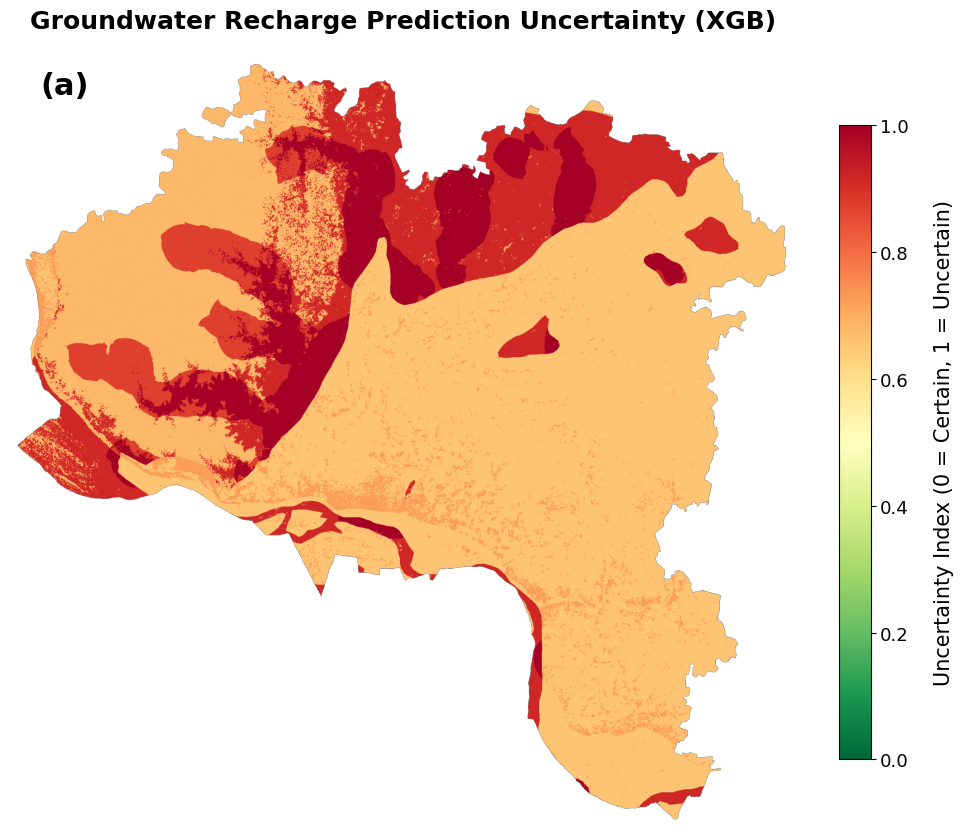

✓ Uncertainty map generated successfully.
Saved at: D:\Thesis\Main\Models\XGBoost\Results\Prediction_Uncertainty_Map11.tif


In [46]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ===============================
# 1. LOAD PROBABILITY MAPS
# ===============================

prob_low_path = r'D:\Thesis\Main\Models\XGBoost\Results\Prob_Low11.tif'
prob_high_path = r'D:\Thesis\Main\Models\XGBoost\Results\Prob_High11.tif'

with rasterio.open(prob_low_path) as src:
    prob_low = src.read(1)
    meta = src.meta.copy()

with rasterio.open(prob_high_path) as src:
    prob_high = src.read(1)

# ===============================
# 2. STACK PROBABILITIES
# ===============================

prob_stack = np.stack([prob_low, prob_high], axis=0)

# ===============================
# 3. SHANNON ENTROPY
# ===============================

epsilon = 1e-10
entropy = -np.sum(prob_stack * np.log(prob_stack + epsilon), axis=0)

# Normalize for 2 classes
max_entropy = np.log(2)
normalized_entropy = entropy / max_entropy

# ===============================
# 4. HANDLE NODATA
# ===============================

nodata_value = meta.get('nodata', -9999)

mask = (prob_low == nodata_value)
normalized_entropy[mask] = nodata_value

meta.update(dtype='float32', nodata=nodata_value)

# ===============================
# 5. SAVE OUTPUT
# ===============================

output_path = r'D:\Thesis\Main\Models\XGBoost\Results\Prediction_Uncertainty_Map11.tif'

with rasterio.open(output_path, 'w', **meta) as dst:
    dst.write(normalized_entropy.astype(np.float32), 1)

# ===============================
# 6. VISUALIZATION (OPTIMIZED FOR JOURNAL SUBMISSION)
# ===============================

# Font Size Configuration
TITLE_FONT = 18
CBAR_LABEL_FONT = 15
CBAR_TICK_FONT = 13
SUBPLOT_LABEL_FONT = 22  # High visibility size for the text label

fig, ax = plt.subplots(figsize=(11, 8.5))

# Plot the map raster, handling NoData values cleanly with np.nan
im = ax.imshow(np.where(normalized_entropy == nodata_value, np.nan, normalized_entropy),
               cmap='RdYlGn_r', vmin=0, vmax=1)
ax.axis('off') 

# Enhanced Colorbar Setup
cbar = fig.colorbar(im, ax=ax, orientation='vertical', pad=0.04, shrink=0.82)

# Modified colorbar label text and size to explicitly reflect recharge dynamics
cbar.set_label(
    'Uncertainty Index (0 = Certain, 1 = Uncertain)', 
    fontsize=CBAR_LABEL_FONT, 
    labelpad=18
)

# Modified colorbar tick mark text size
cbar.ax.tick_params(labelsize=CBAR_TICK_FONT)

# Modified title text and size for scientific accuracy
ax.set_title('Groundwater Recharge Prediction Uncertainty (XGB)', fontsize=TITLE_FONT, fontweight='bold', pad=20)

# --- ADDED SUBPLOT LABEL AREA ---
# Uses transform=ax.transAxes so coordinates are based on the axis box from 0 to 1
# x=-0.05 puts it slightly to the left of the main map area, y=0.98 places it near the top
ax.text(0.1, 0.98, '(a)', 
        transform=ax.transAxes, 
        fontsize=SUBPLOT_LABEL_FONT, 
        fontweight='bold', 
        va='top', 
        ha='right')

# Layout optimization and print-ready export
plt.tight_layout()
plt.savefig(r'D:\Thesis\Main\Models\XGBoost\Results\Uncertainty_Map_Final (a).png', dpi=500, bbox_inches='tight')
plt.show()

print("✓ Uncertainty map generated successfully.")
print("Saved at:", output_path)

C:\Users\HP\AppData\Local\Temp\ipykernel_17872\2537772098.py:30: RuntimeWarning: invalid value encountered in log
  entropy = -np.sum(prob_stack * np.log(prob_stack + epsilon), axis=0)


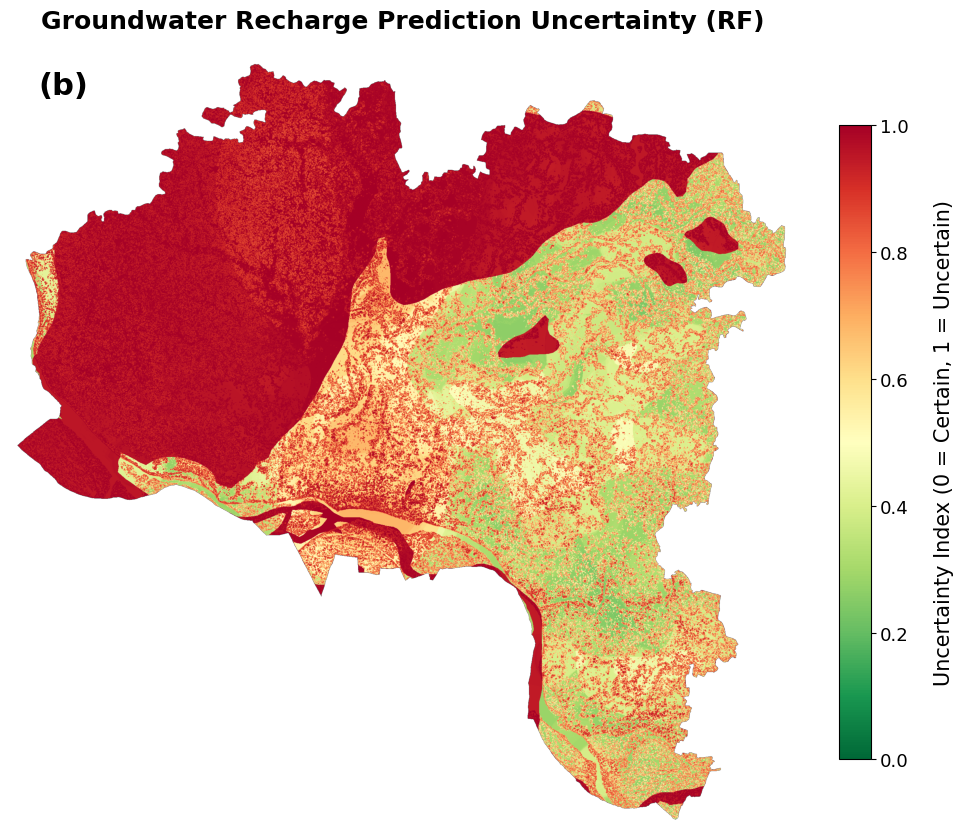

✓ Uncertainty map generated successfully.
Saved at: D:\Thesis\Main\Models\Random Forest\Results\Prediction_Uncertainty_Map.tif


In [48]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ===============================
# 1. LOAD PROBABILITY MAPS
# ===============================

prob_low_path = r'D:\Thesis\Main\Models\Random Forest\Results\Prob_Low.tif'
prob_high_path = r'D:\Thesis\Main\Models\Random Forest\Results\Prob_High.tif'

with rasterio.open(prob_low_path) as src:
    prob_low = src.read(1)
    meta = src.meta.copy()

with rasterio.open(prob_high_path) as src:
    prob_high = src.read(1)

# ===============================
# 2. STACK PROBABILITIES
# ===============================

prob_stack = np.stack([prob_low, prob_high], axis=0)

# ===============================
# 3. SHANNON ENTROPY
# ===============================

epsilon = 1e-10
entropy = -np.sum(prob_stack * np.log(prob_stack + epsilon), axis=0)

# Normalize for 2 classes
max_entropy = np.log(2)
normalized_entropy = entropy / max_entropy

# ===============================
# 4. HANDLE NODATA
# ===============================

nodata_value = meta.get('nodata', -9999)

mask = (prob_low == nodata_value)
normalized_entropy[mask] = nodata_value

meta.update(dtype='float32', nodata=nodata_value)

# ===============================
# 5. SAVE OUTPUT
# ===============================

output_path = r'D:\Thesis\Main\Models\Random Forest\Results\Prediction_Uncertainty_Map.tif'

with rasterio.open(output_path, 'w', **meta) as dst:
    dst.write(normalized_entropy.astype(np.float32), 1)

# ===============================
# 6. VISUALIZATION (OPTIMIZED FOR JOURNAL SUBMISSION)
# ===============================

# 1. Font Size Configuration
TITLE_FONT = 18
CBAR_LABEL_FONT = 15
CBAR_TICK_FONT = 13
SUBPLOT_LABEL_FONT = 22  # High visibility size for the text label

fig, ax = plt.subplots(figsize=(11, 8.5))

# Plot the map raster, handling NoData values cleanly with np.nan and using 'YlOrRd' colormap
im = ax.imshow(np.where(normalized_entropy == nodata_value, np.nan, normalized_entropy),
               cmap='RdYlGn_r', vmin=0, vmax=1)
ax.axis('off') 

# Enhanced Colorbar Setup
cbar = fig.colorbar(im, ax=ax, orientation='vertical', pad=0.04, shrink=0.82)

# Modified colorbar label text and size to explicitly reflect recharge dynamics
cbar.set_label(
    'Uncertainty Index (0 = Certain, 1 = Uncertain)', 
    fontsize=CBAR_LABEL_FONT, 
    labelpad=18
)

# Modified colorbar tick mark text size
cbar.ax.tick_params(labelsize=CBAR_TICK_FONT)

# Modified title text and size for scientific accuracy
ax.set_title('Groundwater Recharge Prediction Uncertainty (RF)', fontsize=TITLE_FONT, fontweight='bold', pad=20)

# --- ADDED SUBPLOT LABEL AREA ---
# Positioned at the top-left edge using axis-relative transAxes coordinates
ax.text(0.1, 0.98, '(b)', 
        transform=ax.transAxes, 
        fontsize=SUBPLOT_LABEL_FONT, 
        fontweight='bold', 
        va='top', 
        ha='right')

# Layout optimization and print-ready export
plt.tight_layout()
plt.savefig(r'D:\Thesis\Main\Models\Random Forest\New Final\Results\Uncertainty_Map_FinalNEW (b).png', dpi=500, bbox_inches='tight')
plt.show()

print("✓ Uncertainty map generated successfully.")
print("Saved at:", output_path)